# INSY 674 — Part E: Hyperparameter Tuning & Feature Importance

**Owner: Person E | Project:** Student Dropout and Academic Success Prediction  
**Connection to Person D:** same 80/20 stratified split (`random_state=42`), same four feature sets, same preprocessing, and 5-fold stratified CV.  
**Scope:** model selection and interpretation **using training data only**; Person F owns the final once-only held-out test evaluation.

### What this notebook produces
1. `RandomizedSearchCV` for D's three shortlisted models: XGBoost, Gradient Boosting, Logistic Regression.
2. A soft-voting ensemble comparison.
3. Fair, fixed-model ablation of academic vs. financial groups (four feature sets).
4. Out-of-fold permutation feature importance, using original (pre-one-hot) columns.
5. Plots, CSVs, a Markdown results report, and a model-selection handoff for Person F.

**Cautions:** The financial features' recording times are unverified; any financial scenario is conditional and should not be described as a confirmed early-warning model. Enrolled is a status observed at the study cutoff, not a known eventual graduation outcome. Cross-validation reuse after tuning can produce optimistic model-selection scores. **No test-set metrics are calculated here.**

**Run:** Put this notebook in `insy674_partb_result/` or the repository root, make sure the existing dataset ZIP is available, install dependencies (`pip install numpy pandas scipy scikit-learn xgboost matplotlib jupyter tabulate`) and select **Run All**. Set `FAST_MODE = True` for a quick preliminary run; use `False` for the final documented run.

## 1. Imports, settings, and reproducible input

We prefer the UCI ZIP already committed to the project. If you have extracted `data.csv`, the notebook can load that instead. Run from the repository root or from `insy674_partb_result/`. The final held-out test subset is created to reproduce D's split but is **never inspected or scored** in this notebook.

In [ ]:
from pathlib import Path
import io, json, zipfile, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
from scipy.stats import loguniform, randint, uniform
from sklearn.base import clone
from sklearn.compose import ColumnTransformer
from sklearn.ensemble import GradientBoostingClassifier, VotingClassifier
from sklearn.impute import SimpleImputer
from sklearn.inspection import permutation_importance
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import make_scorer, recall_score
from sklearn.model_selection import (StratifiedKFold, RandomizedSearchCV,
                                     cross_validate, train_test_split)
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import (FunctionTransformer, LabelEncoder,
                                   OneHotEncoder, StandardScaler)
from xgboost import XGBClassifier

RANDOM_STATE = 42
FAST_MODE = False  # Set True for a quick practice run; set False for final CV/plots.
N_SPLITS = 5  # Matches Person D's five-fold CV even in FAST_MODE.
N_PERM_REPEATS = 2 if FAST_MODE else 4
ITERATIONS = {"XGBoost": 3 if FAST_MODE else 10,
              "Gradient Boosting": 3 if FAST_MODE else 10,
              "Logistic Regression": 3 if FAST_MODE else 8}
CV = StratifiedKFold(n_splits=N_SPLITS, shuffle=True, random_state=RANDOM_STATE)
OUTPUT_DIR = Path('part_e_results')
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

# Search both normal working locations, no absolute personal machine paths.
search_dirs = list(dict.fromkeys([Path.cwd(), Path.cwd().parent, Path.cwd().parent.parent,
                                  Path.cwd() / 'insy674_partb_result']))
zip_candidates = []
csv_candidates = []
for parent in search_dirs:
    if parent.exists():
        zip_candidates.extend(sorted(parent.glob('predict*students*dropout*.zip')))
        csv_candidates.extend([parent / 'data.csv'])

def load_dataset():
    for path in zip_candidates:
        if not path.is_file():
            continue
        with zipfile.ZipFile(path) as archive:
            names = [n for n in archive.namelist() if Path(n).name.lower() == 'data.csv']
            if names:
                with archive.open(names[0]) as fp:
                    data = pd.read_csv(fp, sep=';', encoding='utf-8-sig')
                return data, f'{path} -> {names[0]}'
    for path in csv_candidates:
        if path.is_file():
            return pd.read_csv(path, sep=';', encoding='utf-8-sig'), str(path)
    raise FileNotFoundError('Cannot locate the repository dataset ZIP or data.csv. Run from the repo root or put data.csv beside this notebook.')

df, DATA_SOURCE = load_dataset()
df.columns = df.columns.str.strip().str.replace('\ufeff', '', regex=False)
assert 'Target' in df.columns, 'Expected a Target column.'
assert set(df['Target'].unique()) == {'Dropout', 'Enrolled', 'Graduate'}
print('Data:', DATA_SOURCE, '| shape:', df.shape)
print('Labels:', df['Target'].value_counts().to_dict())

Data: c:\Users\徐子茹\Downloads\INSY674-Student-Dropout-Prediction-main\INSY674-Student-Dropout-Prediction-main\predict+students+dropout+and+academic+success.zip -> data.csv | shape: (4424, 37)
Labels: {'Graduate': 2209, 'Dropout': 1421, 'Enrolled': 794}


## 2. Reconstruct Person C/D's feature sets and leak-safe pipelines

To avoid incompatibilities with Person D's notebook-local functions, we independently recreate the *same* definitions in this notebook. The 18/24/21/27 raw-feature counts are checked. Category codes are one-hot encoded, numerical fields are imputed and scaled, and engineered ratios are built **inside** cross-validation pipelines.

In [2]:
first_sem_cols = [c for c in df.columns if '1st sem' in c]
second_sem_cols = [c for c in df.columns if '2nd sem' in c]
financial_cols = ['Scholarship holder', 'Debtor', 'Tuition fees up to date']
macro_cols = ['Unemployment rate', 'Inflation rate', 'GDP']
admission_cols = [c for c in df.columns if c not in
                  first_sem_cols + second_sem_cols + financial_cols + macro_cols + ['Target']]
first_semester_cols = admission_cols + first_sem_cols
feature_sets = {
    'Admission Only': admission_cols,
    'First Semester': first_semester_cols,
    'Admission + Financial': admission_cols + financial_cols,
    'First Semester + Financial': first_semester_cols + financial_cols,
}
assert {k: len(v) for k, v in feature_sets.items()} == {
    'Admission Only': 18, 'First Semester': 24,
    'Admission + Financial': 21, 'First Semester + Financial': 27
}
for selected in feature_sets.values():
    assert 'Target' not in selected and not set(second_sem_cols).intersection(selected)

categorical_features = [
    'Marital status', 'Application mode', 'Course', 'Daytime/evening attendance',
    'Previous qualification', 'Nacionality', "Mother's qualification",
    "Father's qualification", "Mother's occupation", "Father's occupation",
    'Displaced', 'Educational special needs', 'Debtor', 'Tuition fees up to date',
    'Gender', 'Scholarship holder', 'International'
]

def add_first_semester_features(X):
    X = X.copy()
    enrolled = X['Curricular units 1st sem (enrolled)']
    denominator = enrolled.replace(0, np.nan)
    X['First semester pass rate'] = X['Curricular units 1st sem (approved)'] / denominator
    X['Evaluations per enrolled course'] = X['Curricular units 1st sem (evaluations)'] / denominator
    X['No first-semester enrollment'] = (enrolled == 0).astype(int)
    return X

def make_preprocessor(columns, add_engineered=False):
    cols = list(columns)
    cat_cols = [c for c in cols if c in categorical_features]
    num_cols = [c for c in cols if c not in categorical_features]
    if add_engineered:
        assert set(first_sem_cols).issubset(cols)
        num_cols += ['First semester pass rate', 'Evaluations per enrolled course',
                     'No first-semester enrollment']
    numeric_pipeline = Pipeline([('imputer', SimpleImputer(strategy='median')),
                                 ('scaler', StandardScaler())])
    categorical_pipeline = Pipeline([('imputer', SimpleImputer(strategy='most_frequent')),
                                     ('encoder', OneHotEncoder(handle_unknown='ignore'))])
    transformer = ColumnTransformer([('numeric', numeric_pipeline, num_cols),
                                     ('categorical', categorical_pipeline, cat_cols)])
    steps = []
    if add_engineered:
        steps.append(('feature_engineering', FunctionTransformer(
            add_first_semester_features, validate=False)))
    steps.append(('preprocessing', transformer))
    return Pipeline(steps)

preprocessors = {name: make_preprocessor(cols, 'First Semester' in name)
                 for name, cols in feature_sets.items()}

# Identical split to D; no evaluation on X_test/y_test is permitted in Part E.
X = df.drop(columns=['Target'])
y = df['Target']
X_train, _X_test_reserved_for_F, y_train, _y_test_reserved_for_F = train_test_split(
    X, y, test_size=0.20, random_state=RANDOM_STATE, stratify=y)
label_encoder = LabelEncoder()
y_train_encoded = label_encoder.fit_transform(y_train)
assert list(label_encoder.classes_) == ['Dropout', 'Enrolled', 'Graduate']
dropout_code = int(label_encoder.transform(['Dropout'])[0])
scoring = {
    'f1_macro': 'f1_macro',
    'accuracy': 'accuracy',
    'dropout_recall': make_scorer(recall_score, labels=[dropout_code],
                                  average='macro', zero_division=0)
}
PRIMARY_SET = 'First Semester'  # D's official early-warning shortlist
X_primary = X_train[feature_sets[PRIMARY_SET]]
print('Training rows:', len(X_train), '| Reserved test rows:', len(_X_test_reserved_for_F))
print('First-semester raw columns:', len(feature_sets[PRIMARY_SET]))

Training rows: 3539 | Reserved test rows: 885
First-semester raw columns: 24


## 3. Tune D's shortlisted models with RandomizedSearchCV

D shortlisted **XGBoost, Gradient Boosting, Logistic Regression** on *First Semester* predictors. The primary selection metric is **macro F1**, with dropout recall as a secondary practical metric. Randomized search (rather than an exhaustive grid) explores regularization, tree complexity, boosting rate, and class balance efficiently.

**Protocol:** Each trial refits preprocessing in the corresponding training fold. Mean/SD reported by `RandomizedSearchCV` are *inner CV model-selection* estimates, **not** unbiased final test performance. Person F must evaluate the frozen choice once on the untouched 20%.

In [3]:
models = {
    'XGBoost': XGBClassifier(n_estimators=150, random_state=RANDOM_STATE,
                             n_jobs=1, tree_method='hist', eval_metric='mlogloss'),
    'Gradient Boosting': GradientBoostingClassifier(random_state=RANDOM_STATE),
    'Logistic Regression': LogisticRegression(max_iter=2000, random_state=RANDOM_STATE)
}
parameter_distributions = {
    'XGBoost': {
        'model__n_estimators': randint(80, 261),
        'model__max_depth': randint(2, 6),
        'model__learning_rate': loguniform(0.02, 0.20),
        'model__subsample': uniform(0.65, 0.35),
        'model__colsample_bytree': uniform(0.65, 0.35),
        'model__min_child_weight': randint(1, 9),
        'model__reg_lambda': loguniform(0.3, 30.0),
    },
    'Gradient Boosting': {
        'model__n_estimators': randint(80, 261),
        'model__max_depth': randint(1, 4),
        'model__learning_rate': loguniform(0.02, 0.20),
        'model__subsample': uniform(0.65, 0.35),
        'model__min_samples_leaf': randint(1, 16),
    },
    'Logistic Regression': {
        'model__C': loguniform(0.03, 30.0),
        'model__class_weight': [None, 'balanced'],
    },
}
searches = {}
search_rows = []
for model_name, estimator in models.items():
    pipe = Pipeline([('preprocessing', clone(preprocessors[PRIMARY_SET])),
                     ('model', clone(estimator))])
    search = RandomizedSearchCV(
        estimator=pipe, param_distributions=parameter_distributions[model_name],
        n_iter=ITERATIONS[model_name], cv=CV, scoring='f1_macro', refit=True,
        n_jobs=1, random_state=RANDOM_STATE, error_score='raise',
        return_train_score=True
    )
    print(f'Tuning {model_name} ({ITERATIONS[model_name]} samples x {N_SPLITS} folds) ...')
    search.fit(X_primary, y_train_encoded)
    searches[model_name] = search
    idx = search.best_index_
    search_rows.append({
        'Model': model_name,
        'CV Macro F1 Mean': float(search.cv_results_['mean_test_score'][idx]),
        'CV Macro F1 Std': float(search.cv_results_['std_test_score'][idx]),
        'Train Macro F1 Mean': float(search.cv_results_['mean_train_score'][idx]),
        'Train - CV Gap': float(search.cv_results_['mean_train_score'][idx] -
                               search.cv_results_['mean_test_score'][idx]),
        'Best Params': json.dumps(search.best_params_, sort_keys=True)
    })
    pd.DataFrame(search.cv_results_).to_csv(
        OUTPUT_DIR / f'search_trials_{model_name.lower().replace(" ", "_")}.csv', index=False)

tuning_results = pd.DataFrame(search_rows).sort_values(
    'CV Macro F1 Mean', ascending=False).reset_index(drop=True)
tuning_results.to_csv(OUTPUT_DIR / 'tuning_comparison.csv', index=False)
display(tuning_results[['Model', 'CV Macro F1 Mean', 'CV Macro F1 Std',
                        'Train - CV Gap']].round(4))

Tuning XGBoost (3 samples x 5 folds) ...
Tuning Gradient Boosting (3 samples x 5 folds) ...
Tuning Logistic Regression (3 samples x 5 folds) ...


,Model,CV Macro F1 Mean,CV Macro F1 Std,Train - CV Gap
0,Logistic Regression,0.6452,0.0203,0.0379
1,XGBoost,0.6342,0.0184,0.1671
2,Gradient Boosting,0.6262,0.0142,0.0652


## 4. Report dropout recall and test a soft-voting ensemble

Use **the same five folds** to compare tuned candidates and an ensemble. Each tuned candidate's parameters were chosen on these training rows: subsequent CV scores help choose a final candidate but are *exploratory and selection-optimistic*. Do not report them as held-out test performance. Voting only combines the three selected first-semester candidates, thus no financial-timing assumption is needed.

,Candidate,Macro F1 Mean,Macro F1 Std,Dropout Recall Mean,Dropout Recall Std,Accuracy Mean
0,Soft Voting Ensemble,0.6478,0.0094,0.6965,0.0226,0.7282
1,Logistic Regression,0.6452,0.0203,0.6500,0.0174,0.6928
2,XGBoost,0.6342,0.0184,0.7080,0.0187,0.7268
3,Gradient Boosting,0.6262,0.0142,0.7194,0.0234,0.7262


Provisional winner for Person F to evaluate ONCE: Soft Voting Ensemble


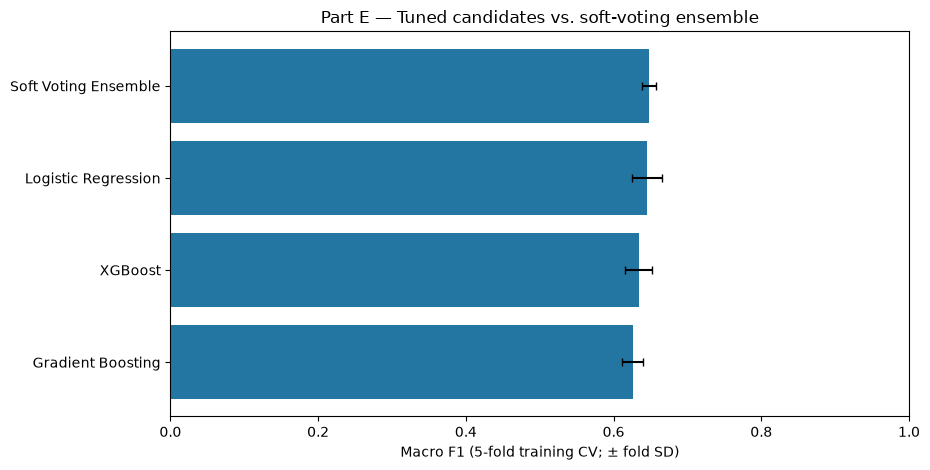

In [5]:
def summarize_cv(name, estimator, features, labels):
    result = cross_validate(estimator, features, labels, cv=CV, scoring=scoring,
                            n_jobs=1, error_score='raise')
    return {
        'Candidate': name,
        'Macro F1 Mean': float(np.mean(result['test_f1_macro'])),
        'Macro F1 Std': float(np.std(result['test_f1_macro'])),
        'Dropout Recall Mean': float(np.mean(result['test_dropout_recall'])),
        'Dropout Recall Std': float(np.std(result['test_dropout_recall'])),
        'Accuracy Mean': float(np.mean(result['test_accuracy'])),
    }

# Fit each voting member through its own cloneable full preprocessing pipeline.
tuned_pipelines = {name: clone(search.best_estimator_)
                   for name, search in searches.items()}
soft_vote = VotingClassifier(
    estimators=[('xgb', clone(tuned_pipelines['XGBoost'])),
                ('gb', clone(tuned_pipelines['Gradient Boosting'])),
                ('lr', clone(tuned_pipelines['Logistic Regression']))],
    voting='soft', n_jobs=1)

candidate_rows = [summarize_cv(n, model, X_primary, y_train_encoded)
                  for n, model in tuned_pipelines.items()]
candidate_rows.append(summarize_cv('Soft Voting Ensemble', soft_vote,
                                   X_primary, y_train_encoded))
candidate_results = pd.DataFrame(candidate_rows).sort_values(
    ['Macro F1 Mean', 'Dropout Recall Mean'], ascending=False).reset_index(drop=True)
candidate_results.to_csv(OUTPUT_DIR / 'candidate_ensemble_cv.csv', index=False)
display(candidate_results.round(4))

WINNER_NAME = str(candidate_results.iloc[0]['Candidate'])
WINNER_PIPELINE = (soft_vote if WINNER_NAME == 'Soft Voting Ensemble'
                   else tuned_pipelines[WINNER_NAME])
print('Provisional winner for Person F to evaluate ONCE:', WINNER_NAME)

plt.figure(figsize=(9.4, 4.8))
plot = candidate_results.sort_values('Macro F1 Mean')
plt.barh(plot['Candidate'], plot['Macro F1 Mean'], xerr=plot['Macro F1 Std'],
         capsize=3, color='#2476a2')
plt.xlabel('Macro F1 (5-fold training CV; ± fold SD)')
plt.title('Part E — Tuned candidates vs. soft-voting ensemble')
plt.xlim(0, 1)
plt.tight_layout()
plt.savefig(OUTPUT_DIR / '01_tuning_and_ensemble.png', dpi=180, bbox_inches='tight')
plt.show()

## 5. Academic vs. financial feature-group comparison (controlled ablation)

We hold the **same Logistic Regression estimator**, split, five CV folds, preprocessing recipe, and macro F1 metric constant while changing **only the input feature group**. This is closer to an incremental-value experiment than comparing individual feature-importance ranks.

- `Admission Only` = 18 candidate enrollment attributes (context/previous academics).
- `First Semester` = above plus 6 first-semester academic results (with three engineered features inside the pipeline).
- `Admission + Financial` = enrollment attributes plus three financial indicators.
- `First Semester + Financial` = first-semester attributes plus three financial indicators.

**Important:** financial feature availability at prediction time has not been verified, and associations are not causal. Do not call admission-only attributes strictly academic-free: previous grades are among them.

,Feature Set,Raw Feature Count,Macro F1 Mean,Macro F1 Std,Dropout Recall Mean,Dropout Recall Std,Accuracy Mean
0,Admission Only,18,0.4924,0.0182,0.5294,0.0393,0.5993
1,First Semester,24,0.6206,0.0099,0.6966,0.0213,0.7152
2,Admission + Financial,21,0.5464,0.0110,0.5980,0.0400,0.6479
3,First Semester + Financial,27,0.6669,0.0148,0.7511,0.0221,0.7525


Additional first-semester academic measurements: Δ Macro F1 = +0.1282
Financial indicators at admission (conditional): Δ Macro F1 = +0.0540
Financial indicators after semester 1 (conditional): Δ Macro F1 = +0.0463


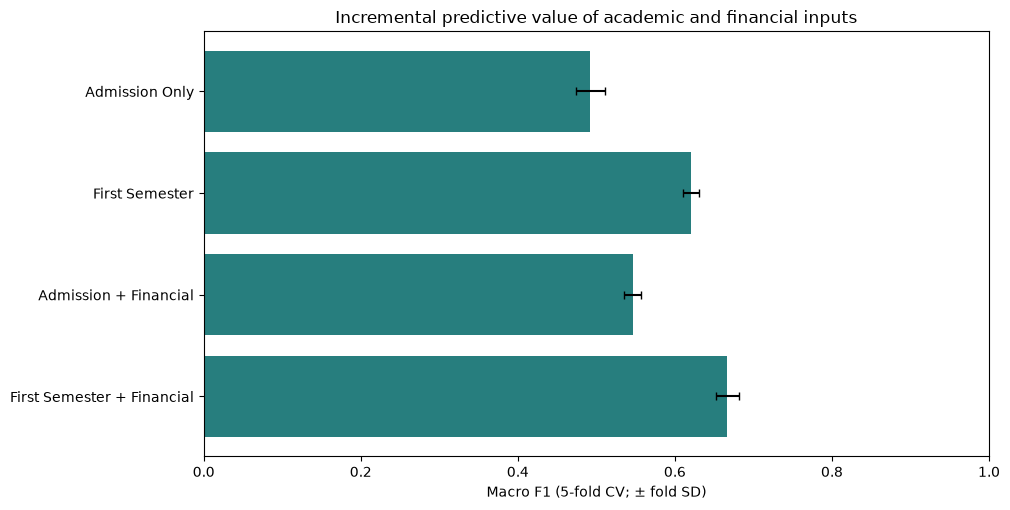

In [6]:
ablation_model = LogisticRegression(max_iter=2000, random_state=RANDOM_STATE)
ablation_rows = []
for set_name, cols in feature_sets.items():
    pipeline = Pipeline([('preprocessing', clone(preprocessors[set_name])),
                         ('model', clone(ablation_model))])
    row = summarize_cv(set_name, pipeline, X_train[cols], y_train_encoded)
    ablation_rows.append({'Feature Set': set_name, 'Raw Feature Count': len(cols),
                          **{k: v for k, v in row.items() if k != 'Candidate'}})
ablation_results = pd.DataFrame(ablation_rows).set_index('Feature Set').reindex(
    list(feature_sets)).reset_index()
ablation_results.to_csv(OUTPUT_DIR / 'academic_financial_ablation.csv', index=False)
display(ablation_results.round(4))

f1_by_set = ablation_results.set_index('Feature Set')['Macro F1 Mean']
academic_gain = f1_by_set['First Semester'] - f1_by_set['Admission Only']
financial_gain_admission = f1_by_set['Admission + Financial'] - f1_by_set['Admission Only']
financial_gain_semester = (f1_by_set['First Semester + Financial'] -
                           f1_by_set['First Semester'])
print(f'Additional first-semester academic measurements: Δ Macro F1 = {academic_gain:+.4f}')
print(f'Financial indicators at admission (conditional): Δ Macro F1 = {financial_gain_admission:+.4f}')
print(f'Financial indicators after semester 1 (conditional): Δ Macro F1 = {financial_gain_semester:+.4f}')

plt.figure(figsize=(10.2, 5.2))
plt.barh(ablation_results['Feature Set'], ablation_results['Macro F1 Mean'],
         xerr=ablation_results['Macro F1 Std'], color='#277e7e', capsize=3)
plt.xlim(0, 1)
plt.xlabel('Macro F1 (5-fold CV; ± fold SD)')
plt.title('Incremental predictive value of academic and financial inputs')
plt.gca().invert_yaxis()
plt.tight_layout()
plt.savefig(OUTPUT_DIR / '02_feature_group_ablation.png', dpi=180, bbox_inches='tight')
plt.show()

## 6. Feature importance from held-out training folds, NOT the final test set

Permutation importance asks how much a model's macro F1 changes when an **original input column is shuffled on a validation fold**. The entire pipeline receives that column, so one-hot expansion and engineered features are handled correctly. Positive importance means worse predictions after shuffling; small/negative numbers do not reliably imply a meaningful effect. Correlated predictors can share importance.

We evaluate the **best tuned single model** (rather than the ensemble) for clearer interpretation, on the 24 raw first-semester inputs. Then we separately examine a conditional **First Semester + Financial** logistic model to interpret financial predictors. These are predictive associations, not causal evidence.

Permutation importance for best single tuned model: Logistic Regression
  First Semester: finished fold 1/5
  First Semester: finished fold 2/5
  First Semester: finished fold 3/5
  First Semester: finished fold 4/5
  First Semester: finished fold 5/5


,Feature,Mean,Std
0,Curricular units 1st sem (approved),0.2217,0.0318
1,Curricular units 1st sem (grade),0.0425,0.0128
2,Curricular units 1st sem (enrolled),0.0318,0.0069
3,Curricular units 1st sem (evaluations),0.0229,0.0195
4,Course,0.0225,0.0120
5,Curricular units 1st sem (credited),0.0158,0.0070
6,Application mode,0.0114,0.0071
7,Age at enrollment,0.0111,0.0080
8,Previous qualification,0.0060,0.0043
9,Daytime/evening attendance,0.0052,0.0043


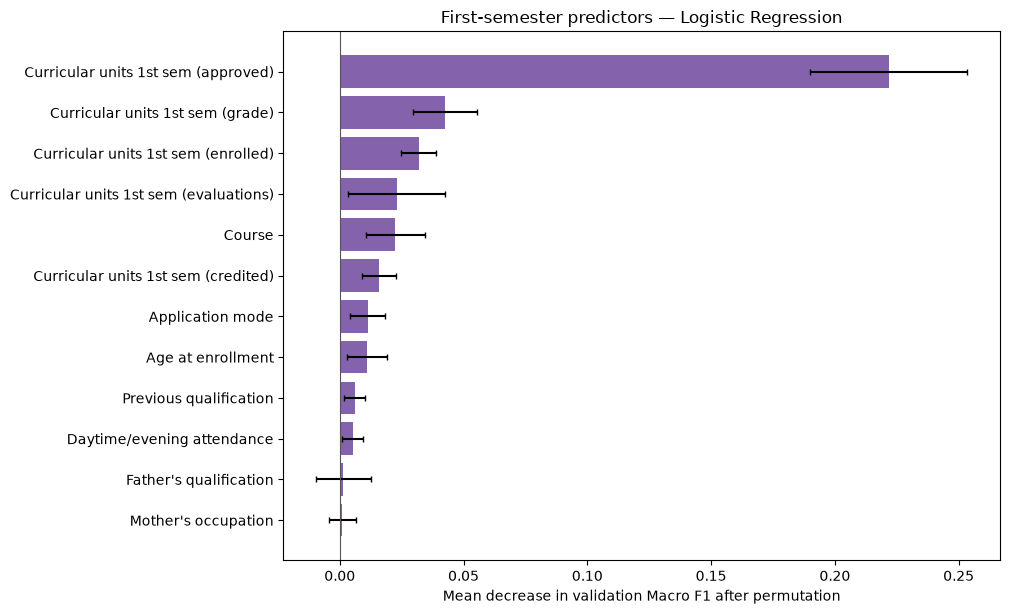

In [7]:
single_model_name = str(tuning_results.iloc[0]['Model'])
single_estimator = clone(tuned_pipelines[single_model_name])

def cv_permutation_importance(pipeline, set_name, repeats=N_PERM_REPEATS):
    columns = list(feature_sets[set_name])
    X_set = X_train[columns]
    rows = []
    for fold, (train_idx, val_idx) in enumerate(CV.split(X_set, y_train_encoded), start=1):
        fitted = clone(pipeline).fit(X_set.iloc[train_idx], y_train_encoded[train_idx])
        importance = permutation_importance(
            fitted, X_set.iloc[val_idx], y_train_encoded[val_idx],
            scoring='f1_macro', n_repeats=repeats, random_state=RANDOM_STATE + fold,
            n_jobs=1)
        for feat, vals in zip(columns, importance.importances):
            rows.extend({'Feature': feat, 'Fold': fold, 'Importance': float(x)} for x in vals)
        print(f'  {set_name}: finished fold {fold}/{N_SPLITS}')
    raw = pd.DataFrame(rows)
    summary = (raw.groupby('Feature')['Importance']
               .agg(Mean='mean', Std='std').sort_values('Mean', ascending=False)
               .reset_index())
    return raw, summary

print('Permutation importance for best single tuned model:', single_model_name)
primary_perm_raw, primary_importance = cv_permutation_importance(single_estimator, PRIMARY_SET)
primary_perm_raw.to_csv(OUTPUT_DIR / 'perm_primary_fold_values.csv', index=False)
primary_importance.to_csv(OUTPUT_DIR / 'perm_primary_summary.csv', index=False)
display(primary_importance.head(15).round(4))

def plot_importance(table, title, filename, top=12):
    subset = table.head(top).iloc[::-1]
    plt.figure(figsize=(10.2, max(4, top * 0.42 + 1.2)))
    plt.barh(subset['Feature'], subset['Mean'], xerr=subset['Std'].fillna(0),
             color='#8463ac', capsize=2)
    plt.axvline(0, color='#555', linewidth=0.8)
    plt.xlabel('Mean decrease in validation Macro F1 after permutation')
    plt.title(title)
    plt.tight_layout()
    plt.savefig(OUTPUT_DIR / filename, dpi=180, bbox_inches='tight')
    plt.show()

plot_importance(primary_importance, f'First-semester predictors — {single_model_name}',
                '03_primary_feature_importance.png')

## 7. Conditional financial-feature importance

This companion chart *only* shows the conditional scenario with first-semester results plus three financial fields. Its purpose is descriptive; **the recording dates of financial fields have not been validated**. Financial features cannot be claimed deployable at enrollment or at semester 1 unless the source institution confirms availability.

  First Semester + Financial: finished fold 1/5
  First Semester + Financial: finished fold 2/5
  First Semester + Financial: finished fold 3/5
  First Semester + Financial: finished fold 4/5
  First Semester + Financial: finished fold 5/5


,Feature,Mean,Std
0,Curricular units 1st sem (approved),0.1937,0.0296
1,Tuition fees up to date,0.0501,0.0095
2,Curricular units 1st sem (grade),0.0455,0.0099
3,Curricular units 1st sem (enrolled),0.0308,0.0113
4,Course,0.0299,0.0095
5,Curricular units 1st sem (evaluations),0.0168,0.0139
6,Application mode,0.0164,0.0114
7,Curricular units 1st sem (credited),0.0136,0.0067
8,Father's occupation,0.0127,0.0145
9,Age at enrollment,0.0113,0.0096


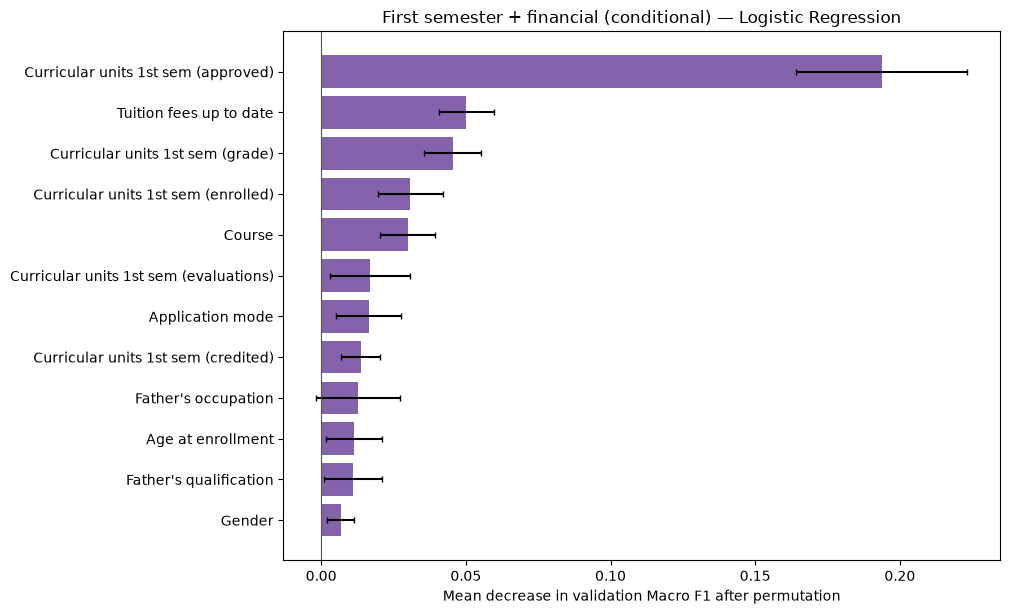

Financial feature ranks:


,Feature,Rank,Mean,Std
1,Tuition fees up to date,2,0.0501,0.0095
12,Scholarship holder,13,0.0063,0.0040
17,Debtor,18,0.0029,0.0047


In [8]:
FULL_SET = 'First Semester + Financial'
financial_pipeline = Pipeline([
    ('preprocessing', clone(preprocessors[FULL_SET])),
    ('model', LogisticRegression(max_iter=2000, random_state=RANDOM_STATE))
])
finance_perm_raw, finance_importance = cv_permutation_importance(financial_pipeline, FULL_SET)
finance_perm_raw.to_csv(OUTPUT_DIR / 'perm_financial_fold_values.csv', index=False)
finance_importance.to_csv(OUTPUT_DIR / 'perm_financial_summary.csv', index=False)
display(finance_importance.head(15).round(4))

plot_importance(finance_importance, 'First semester + financial (conditional) — Logistic Regression',
                '04_conditional_financial_importance.png')
print('Financial feature ranks:')
display(finance_importance.assign(Rank=np.arange(1, len(finance_importance) + 1))
        .query('Feature in @financial_cols')[['Feature', 'Rank', 'Mean', 'Std']].round(4))

## 8. Generate a ready-to-edit Results / Interpretation section and Person F handoff

The report embeds numbers actually computed when you run the notebook and links to saved figures. Share `part_e_results/` and this notebook with A/F. **Do not manually invent post-tuning results.**

Selection caution: Winner and scores come from training-data CV used for both tuning and comparing, so they are not unbiased external generalization estimates. The final once-only test result and interpretation belong to F.

In [9]:
top_features = primary_importance.head(8)['Feature'].tolist()
top_financial = finance_importance[finance_importance['Feature'].isin(financial_cols)]

report = f"""# Part E — Hyperparameter Tuning and Feature Importance

## Objective and reproducibility
We build on Person D's stratified 80/20 split (seed 42), 5-fold stratified CV, and four predeclared feature sets. Only training rows are used in this part. We compare models by macro F1, with dropout recall as an operational secondary metric. The final test set is reserved for Person F.

## Hyperparameter tuning (First Semester, no financial indicators)
We applied RandomizedSearchCV with five stratified folds to the three models shortlisted by D: XGBoost, Gradient Boosting, and Logistic Regression. Search spaces addressed model complexity, learning rate, regularization, and (for logistic regression) class weighting. This is a randomized search of a bounded hyperparameter space, not an exhaustive optimization or a causal experiment.

{tuning_results[['Model', 'CV Macro F1 Mean', 'CV Macro F1 Std', 'Train - CV Gap']].round(4).to_markdown(index=False)}

Figure: ![Tuned model and ensemble comparison](01_tuning_and_ensemble.png)

## Soft-voting ensemble and model selection
A three-model soft-voting ensemble was compared with each tuned model using the same first-semester inputs and five-fold CV.

{candidate_results.round(4).to_markdown(index=False)}

**Provisional training-CV choice:** {WINNER_NAME}. These cross-validation results help with selection but may be optimistic because the same training data informs tuning and selection. Person F must evaluate the locked model once on the untouched held-out test set. No final-test performance claim is made here.

## Incremental academic and financial information
To hold modeling conditions constant, we compared all four feature sets using the same untuned Logistic Regression estimator and the same five stratified folds:

{ablation_results[['Feature Set','Raw Feature Count','Macro F1 Mean','Macro F1 Std','Dropout Recall Mean']].round(4).to_markdown(index=False)}

- Adding first-semester academic results to admission context: Δ macro F1 = **{academic_gain:+.4f}**.
- Adding financial variables to admission context: Δ macro F1 = **{financial_gain_admission:+.4f}** (conditional on verified timing).
- Adding financial variables to first-semester context: Δ macro F1 = **{financial_gain_semester:+.4f}** (conditional on verified timing).

![Feature-set CV comparison](02_feature_group_ablation.png)

This is a comparison of predictive contributions under a fixed-model CV setup. The admission group already includes some academic-background attributes, so the academic delta specifically measures **added first-semester observations**. The financial fields (scholarship, debtor, tuition-payment status) have unverified recording times. Do not interpret these associations as causal effects or proven deployable early-warning inputs.

## Feature importance
For interpretability we computed permutation importance on training-held-out CV folds using the best tuned single model ({single_model_name}) and reported the reduction in validation macro F1 when an original column was shuffled. The top eight columns were: **{', '.join(top_features)}**.

![First-semester permutation importance](03_primary_feature_importance.png)

A separate conditional model using First Semester + Financial was interpreted to examine the three finance-related columns:

{top_financial.round(4).to_markdown(index=False)}

![Financial-scenario permutation importance](04_conditional_financial_importance.png)

Permutation importance is model-specific and may distribute importance across correlated inputs; it does not imply causality or justify an individual-level intervention by itself.

## Limitations and next step for Person F
- Hyperparameter selection and model comparison reuse the training folds; reported CV results are exploratory model-selection metrics and potentially optimistic.
- The Enrolled label does not settle students' eventual outcomes. Its class-specific performance should be explicitly reported by F.
- Financial administrative timestamps are unverified. The **main** selected first-semester modeling scenario intentionally excludes the financial variables.
- No held-out test scores were calculated in E. F should take the frozen selection from `model_selection_for_F.json`, reproduce the training pipeline, evaluate once, and discuss confusion matrices, recall/F1, and realistic limitations.
- Before finalizing, A/E should verify all rubric items and ensure the repository contains final documentation and evidence figures.
"""
(OUTPUT_DIR / 'PART_E_REPORT.md').write_text(report, encoding='utf-8')

params = {name: s.best_params_ for name, s in searches.items()}
handoff = {
    'selection_feature_set': PRIMARY_SET,
    'feature_columns': list(feature_sets[PRIMARY_SET]),
    'chosen_candidate': WINNER_NAME,
    'tuned_parameters': params,
    'train_test_split': {'test_size': 0.2, 'stratify': 'Target', 'random_state': RANDOM_STATE},
    'cv': {'n_splits': N_SPLITS, 'shuffle': True, 'random_state': RANDOM_STATE},
    'primary_selection_metric': 'macro F1',
    'important_note': 'CV selection only. Held-out test set NOT accessed in Part E.',
    'financial_features_timing_verified': False,
    'fast_mode': FAST_MODE,
}
(OUTPUT_DIR / 'model_selection_for_F.json').write_text(
    json.dumps(handoff, indent=2, ensure_ascii=False), encoding='utf-8')
print('Saved', OUTPUT_DIR / 'PART_E_REPORT.md')
print('Saved', OUTPUT_DIR / 'model_selection_for_F.json')
print('Saved CSV and figures in', OUTPUT_DIR.resolve())

Saved part_e_results\PART_E_REPORT.md
Saved part_e_results\model_selection_for_F.json
Saved CSV and figures in C:\Users\徐子茹\Downloads\INSY674-Student-Dropout-Prediction-main\INSY674-Student-Dropout-Prediction-main\insy674_partb_result\part_e_results


## 9. Person E rubric / handoff checklist

- [ ] **A — Framing:** Clear objective, users, supervised offline multiclass rationale, why macro F1 and dropout recall, deployment assumptions.
- [ ] **B — Exploration:** Each attribute profiled; labeled plots; target imbalance, correlations, insights; potential leakage/recording-time issues acknowledged.
- [ ] **C — Data prep:** Consistent split; fold-internal imputation, one-hot encoding, scaling, feature engineering; no second-semester predictors.
- [ ] **D — Compare models:** Multiple families, 5-fold mean ± SD, majority-class baseline, error types, three promising candidates.
- [ ] **E — Fine-tune:** Run final version (`FAST_MODE=False`), saved search tables, ensemble, feature-set ablation, permutation importance, selection justification.
- [ ] **F — Final eval:** **Only F** evaluates the frozen model on the held-out test set; confusion matrix, class-level F1/recall, limitation analysis.
- [ ] **PPT & README:** Each person supplies their section; A integrates README, B formats PPT, F integrates and reviews; team GitHub IDs and repository URL included in presentation submission.
- [ ] **Deadline:** Course page says **Oct 29, 2026 at 11:59 PM**; final repo state at deadline matters. Confirm course timezone/platform submission status.

### Suggested two-slide narrative
**Slide E1 — Does tuning/ensembling help?** Show `01_tuning_and_ensemble.png`. Message: We tuned D's three shortlisted models by five-fold randomized CV and compared a soft-voting ensemble. Report winner **only after running E**. Note D's untuned first-semester XGBoost macro F1 was 0.6320; this is not an identical unbiased head-to-head after selection.

**Slide E2 — Which information adds value?** Show `02_feature_group_ablation.png` plus up to five items from `03_primary_feature_importance.png`. Say adding first-semester information is an incremental comparison over admission background; financial gains are conditional on unverified recording dates. Avoid causal language.

**Handoff:** Share Part E notebook + `part_e_results/` with A/F and let F perform the one-time test evaluation.